In [32]:
from IPython.display import display
import json
import io
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import plotly.express as px
from skimage.metrics import mean_squared_error as mse
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.util import crop
from scipy import ndimage, datasets
from scipy.ndimage import uniform_filter, gaussian_filter
import yuvio
import y4m
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({"axes.spines.top": False,
                     "axes.spines.right": False})

# Intro

In [33]:
# Essa linha mostra todos os Light Fields que rodei na lfc-toolkit, com diferentes taxas de compressão,
# e passa o nome deles para txt.txt, da pra ver os 10 primeiros na próxima célula
!ls ../jpeg-pleno-ctc-tools/lfc_toolkit/examples/results/jplm/metrics_report/vmaf/ > txt.txt

In [34]:
!ls ../jpeg-pleno-ctc-tools/lfc_toolkit/examples/results/jplm/metrics_report/vmaf/ | head

Bikes_015_vmaf_11_11_625x434_yuv444p10le.json
Bikes_03_vmaf_11_11_625x434_yuv444p10le.json
Bikes_12_vmaf_11_11_625x434_yuv444p10le.json
Bikes_3_vmaf_11_11_625x434_yuv444p10le.json
Bikes_96_vmaf_11_11_625x434_yuv444p10le.json
Danger_de_Mort_015_vmaf_11_11_625x434_yuv444p10le.json
Danger_de_Mort_03_vmaf_11_11_625x434_yuv444p10le.json
Danger_de_Mort_12_vmaf_11_11_625x434_yuv444p10le.json
Danger_de_Mort_3_vmaf_11_11_625x434_yuv444p10le.json
Danger_de_Mort_96_vmaf_11_11_625x434_yuv444p10le.json


In [35]:
# essa célula abre o txt.txt, lê as linhas e passa pra uma lista os nomes
path_jpeg = '../jpeg-pleno-ctc-tools/lfc_toolkit/examples/results/jplm/metrics_report/vmaf/'

f = open(path_jpeg + 'txt.txt', 'r')  
texto = f.read()
all_LFs = texto.split('\n')
all_LFs = [i for i in all_LFs if '4' in i]
all_LFs[:10]

['Bikes_015_vmaf_11_11_625x434_yuv444p10le.json',
 'Bikes_03_vmaf_11_11_625x434_yuv444p10le.json',
 'Bikes_12_vmaf_11_11_625x434_yuv444p10le.json',
 'Bikes_3_vmaf_11_11_625x434_yuv444p10le.json',
 'Bikes_96_vmaf_11_11_625x434_yuv444p10le.json',
 'Danger_de_Mort_015_vmaf_11_11_625x434_yuv444p10le.json',
 'Danger_de_Mort_03_vmaf_11_11_625x434_yuv444p10le.json',
 'Danger_de_Mort_12_vmaf_11_11_625x434_yuv444p10le.json',
 'Danger_de_Mort_3_vmaf_11_11_625x434_yuv444p10le.json',
 'Danger_de_Mort_96_vmaf_11_11_625x434_yuv444p10le.json']

In [36]:
# Aqui eu armazeno na variável LightField_names apenas os nome dos Light Fields + suas taxas de compressão
LightField_names = [lf.split('_vmaf')[0] for lf in all_LFs]
LightField_names[:10]

['Bikes_015',
 'Bikes_03',
 'Bikes_12',
 'Bikes_3',
 'Bikes_96',
 'Danger_de_Mort_015',
 'Danger_de_Mort_03',
 'Danger_de_Mort_12',
 'Danger_de_Mort_3',
 'Danger_de_Mort_96']

In [37]:
# Nessa célula eu obtenho todos os valores do PSNR_y e SSIM
# para cada view de cada LF, que foi rodada pelo lfctoolkit. 
# PS: não sei como o SSIM foi calculado
ssim_dict_of_each_LF = {}
psnr_dict_of_each_LF = {}

for each_LF, LF_name in zip(all_LFs, LightField_names):
    ssim_list_of_each_view_per_LF = []
    psnr_list_of_each_view_per_LF = []
    
    # Lembrando path_jpeg = '../jpeg-pleno-ctc-tools/lfc_toolkit/examples/results/jplm/metrics_report/vmaf/'
    path_corrigido = os.path.join(path_jpeg + each_LF)
    
    with open(path_corrigido) as f:
        
        for linha in f:  # 1 line is exactly like '         "integer_adm_scale0": 0.888848,'
            par = linha.strip()[:-1].split(': ')  # which par is ['"integer_adm_scale0"', '0.888848']

            try:
                if par[0] == '"float_ssim"':
                    ssim_list_of_each_view_per_LF.append(float(par[1]))
                elif par[0] == '"psnr_y"':
                    psnr_list_of_each_view_per_LF.append(float(par[1]))
                    
            except:
                continue
                
    ssim_dict_of_each_LF[LF_name] = ssim_list_of_each_view_per_LF
    psnr_dict_of_each_LF[LF_name] = psnr_list_of_each_view_per_LF

mean_psnr_y_bikes015 = np.mean(psnr_dict_of_each_LF['Bikes_015'])
print('mean_psnr_y_bikes015 ', mean_psnr_y_bikes015) # verified some cells bellow

mean_ssim_bikes015 = np.mean(ssim_dict_of_each_LF['Bikes_015'])
print('mean_ssim_bikes015 ', mean_ssim_bikes015) # verified some cells below
print('\nBikes_015:', psnr_dict_of_each_LF['Bikes_015'])

mean_psnr_y_bikes015  29.99465495041322
mean_ssim_bikes015  0.9303986280991735

Bikes_015: [28.208347, 29.35228, 29.814472, 29.902728, 29.893179, 29.921376, 30.004367, 30.047687, 29.970585, 29.569613, 28.223673, 29.405722, 30.265871, 30.43936, 30.42555, 30.370664, 30.336209, 30.334539, 30.337683, 30.255453, 30.093684, 29.274278, 29.712374, 30.140608, 30.440398, 30.53433, 30.424018, 30.351452, 30.342352, 30.353098, 30.406911, 30.364091, 29.869671, 30.016113, 30.334002, 30.271592, 30.257165, 30.281573, 30.2571, 30.306114, 30.502057, 30.513733, 30.077092, 29.62244, 29.516392, 30.032605, 30.460147, 30.341195, 30.139692, 30.153012, 30.229714, 30.208575, 30.185208, 30.292704, 30.080113, 30.131625, 30.36556, 30.257013, 30.251217, 30.209943, 30.079223, 30.06951, 30.285845, 30.412492, 29.979754, 29.466994, 29.50123, 29.893939, 30.333698, 30.32802, 30.122762, 30.07845, 30.176315, 30.30813, 30.365797, 30.451933, 30.129637, 30.084412, 30.509948, 30.499715, 30.40151, 30.259956, 30.21242, 30.26985, 

\
Quero fazer um DataFrame com todos os dados, ou seja, cujas linhas sejam cada Light Field com sua respectiva taxa, e cada coluna um valor do SSIM ou do PSNR_y de cada view. Como os LFs tem quantidades de views diferentes, vou completá-los com nulos pra terem as mesmas dimensões

In [38]:
ssim_df = pd.DataFrame.from_dict(ssim_dict_of_each_LF, orient = 'index')
ssim_df.columns = [f'view_{i}' for i in ssim_df.columns]

ssim_df['media'] = ssim_df.mean(axis = 1, skipna = True)

print(ssim_df.shape)
ssim_df.index.name = 'ssim'
ssim_df[['view_0', 'view_1', 'view_2', 'view_3', 'media']].head(10)

(45, 962)


,view_0,view_1,view_2,view_3,media
ssim,,,,,
Bikes_015,0.910789,0.920647,0.925464,0.926935,0.930399
Bikes_03,0.942292,0.953586,0.957116,0.957668,0.959361
Bikes_12,0.975320,0.983393,0.985195,0.985290,0.985855
Bikes_3,0.987100,0.991931,0.992668,0.992699,0.992880
Bikes_96,0.994603,0.996540,0.996669,0.996760,0.996798
Danger_de_Mort_015,0.887334,0.898359,0.902206,0.904826,0.907946
Danger_de_Mort_03,0.924960,0.941594,0.946611,0.947586,0.949744
Danger_de_Mort_12,0.966737,0.980839,0.983225,0.982586,0.983961
Danger_de_Mort_3,0.981647,0.990034,0.991154,0.990818,0.991486


Esse dataframe é o ssim de cada view de cada LF

$$
$$

Agora vou fazer o Data Frame pro PSNR_y

In [39]:
psnr_df = pd.DataFrame.from_dict(psnr_dict_of_each_LF, orient = 'index')
psnr_df.columns = [f'view_{i}' for i in psnr_df.columns]
psnr_df.index.name = 'psnr'
psnr_df['media'] = psnr_df.mean(axis = 1, skipna = True)
psnr_df[['view_0', 'view_1', 'view_2', 'view_3', 'media']].head(10)

,view_0,view_1,view_2,view_3,media
psnr,,,,,
Bikes_015,28.208347,29.352280,29.814472,29.902728,29.994655
Bikes_03,30.197260,31.618555,31.987250,32.016086,32.119823
Bikes_12,34.184410,35.814774,36.120128,36.135778,36.374724
Bikes_3,36.974527,38.632188,38.895819,38.965575,39.213196
Bikes_96,40.737275,42.185595,42.278180,42.434652,42.693863
Danger_de_Mort_015,27.018145,27.569523,27.827373,28.016030,28.167653
Danger_de_Mort_03,28.825864,29.795106,30.149151,30.263467,30.347308
Danger_de_Mort_12,32.627688,34.419230,34.701126,34.542754,34.881390
Danger_de_Mort_3,35.403706,37.391355,37.564641,37.382523,37.799623


Pra verificar se fiz corretamente, podemos ver no json do `Bikes_015` que tanto a média do PSNR_y quanto o SSIM batem com o valor dos dfs

In [40]:
!cd ../jpeg-pleno-ctc-tools/lfc_toolkit/examples/results/jplm/metrics_report/vmaf/\
&& tail -n 34 Bikes_015_vmaf_11_11_625x434_yuv444p10le.json\
| head -n 5\
&& tail -n 16 Bikes_015_vmaf_11_11_625x434_yuv444p10le.json\
| head -n 5

    "psnr_y": {
      "min": 26.050358,
      "max": 30.561557,
      "mean": 29.994655,
      "harmonic_mean": 29.981827
    "float_ssim": {
      "min": 0.871842,
      "max": 0.938101,
      "mean": 0.930399,
      "harmonic_mean": 0.930361


---
Agora a tarefa é outra.

Quando eu rodei o lfctoolkit, uma das modificações foi de estimar a SSIM. Que podem ser vistas como na célula seguinte.

In [41]:
!cd ../lfctest/ce/results/jplm_ssim_estimate_results/ && head */logs/Bikes_015_11_11_625x434_PGX.json

{
    "lambda": 79641.643381,
    "est_ssim": 0.9830602176303537
}

Na proxima célula eu busco por todas os jsons processados. Como não consegui passar pra um txt e fazer como fiz na primeira parte, a solução foi fz de forma manual. Copiei e colei em uma string e depois fiz a divisão com python


In [42]:
!cd ../lfctest/ce/results/jplm_ssim_estimate_results/ && echo */logs/*.json

Bikes/logs/Bikes_015_11_11_625x434_PGX.json Bikes/logs/Bikes_03_11_11_625x434_PGX.json Bikes/logs/Bikes_12_11_11_625x434_PGX.json Bikes/logs/Bikes_3_11_11_625x434_PGX.json Bikes/logs/Bikes_96_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_015_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_03_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_12_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_3_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_96_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_015_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_03_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_12_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_3_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_96_11_11_625x434_PGX.json greek/logs/greek_005_9_9_512x512_PGX.json greek/logs/greek_0075_9_9_512x512_PGX.json greek/logs/greek_015_9_9_512x512_PGX.json greek/logs/greek_0

In [43]:
_ = 'Bikes/logs/Bikes_015_11_11_625x434_PGX.json Bikes/logs/Bikes_03_11_11_625x434_PGX.json Bikes/logs/Bikes_12_11_11_625x434_PGX.json Bikes/logs/Bikes_3_11_11_625x434_PGX.json Bikes/logs/Bikes_96_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_015_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_03_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_12_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_3_11_11_625x434_PGX.json Danger_de_Mort/logs/Danger_de_Mort_96_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_015_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_03_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_12_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_3_11_11_625x434_PGX.json Fountain_Vincent2/logs/Fountain_Vincent2_96_11_11_625x434_PGX.json greek/logs/greek_005_9_9_512x512_PGX.json greek/logs/greek_0075_9_9_512x512_PGX.json greek/logs/greek_015_9_9_512x512_PGX.json greek/logs/greek_03_9_9_512x512_PGX.json greek/logs/greek_12_9_9_512x512_PGX.json set2/logs/set2_005_33_11_1920x1080_PGX.json set2/logs/set2_0075_33_11_1920x1080_PGX.json set2/logs/set2_015_33_11_1920x1080_PGX.json set2/logs/set2_03_33_11_1920x1080_PGX.json set2/logs/set2_12_33_11_1920x1080_PGX.json sideboard/logs/sideboard_015_9_9_512x512_PGX.json sideboard/logs/sideboard_03_9_9_512x512_PGX.json sideboard/logs/sideboard_12_9_9_512x512_PGX.json sideboard/logs/sideboard_3_9_9_512x512_PGX.json sideboard/logs/sideboard_96_9_9_512x512_PGX.json Stone_Pillars_Outside/logs/Stone_Pillars_Outside_015_11_11_625x434_PGX.json Stone_Pillars_Outside/logs/Stone_Pillars_Outside_03_11_11_625x434_PGX.json Stone_Pillars_Outside/logs/Stone_Pillars_Outside_12_11_11_625x434_PGX.json Stone_Pillars_Outside/logs/Stone_Pillars_Outside_3_11_11_625x434_PGX.json Stone_Pillars_Outside/logs/Stone_Pillars_Outside_96_11_11_625x434_PGX.json tarot/logs/tarot_005_17_17_1024x1024_PGX.json tarot/logs/tarot_0075_17_17_1024x1024_PGX.json tarot/logs/tarot_015_17_17_1024x1024_PGX.json tarot/logs/tarot_03_17_17_1024x1024_PGX.json tarot/logs/tarot_12_17_17_1024x1024_PGX.json'
LFs = _.split(' ')

path_lfc = '../lfctest/ce/results/jplm_ssim_estimate_results/'

LFs[:5]

['Bikes/logs/Bikes_015_11_11_625x434_PGX.json',
 'Bikes/logs/Bikes_03_11_11_625x434_PGX.json',
 'Bikes/logs/Bikes_12_11_11_625x434_PGX.json',
 'Bikes/logs/Bikes_3_11_11_625x434_PGX.json',
 'Bikes/logs/Bikes_96_11_11_625x434_PGX.json']

In [44]:
# Nessa célula eu coleto o SSIM estimado para os LFs, no geral, e não por view.
ssim_estimados_dict_por_lf = {}

for lf in LFs:

    path_corrigido = os.path.join(path_lfc + lf)     
    lf_nome_lista = lf.split('/')[2].split('_')[:-4] # Lembrando que cada lf é um elemento
    lf_nome = ''  # da celula anterior. Ex: 'Bikes/logs/Bikes_03_11_11_625x434_PGX.json'
    # print(lf_nome_lista) retorna ['Bikes', '015']
    
    for i in lf_nome_lista:
        lf_nome += i + '_'
        
    with open(path_corrigido, 'r') as f:
        
        for line in f:
            par = line.strip().split(': ')  # ['"est_ssim"', '0.9830602176303537']
            
            try:
                ssim_estimados_dict_por_lf[lf_nome[:-1]] = float(par[1])
            
            except:
                continue

ssim_estimados_df = pd.DataFrame(ssim_estimados_dict_por_lf, index = ['ssim_estimados_dict_por_lf']).T
ssim_estimados_df.columns = ['ssim_estimado']
ssim_estimados_df.head()

,ssim_estimado
Bikes_015,0.983060
Bikes_03,0.989592
Bikes_12,0.996093
Bikes_3,0.997971
Bikes_96,0.999095


In [45]:
df_merged = pd.concat([ssim_estimados_df, ssim_df[['media']]], axis=1, join='outer')
df_merged.columns = ['ssim_estimado', 'ssim_original']
df_merged.head()

,ssim_estimado,ssim_original
Bikes_015,0.983060,0.930399
Bikes_03,0.989592,0.959361
Bikes_12,0.996093,0.985855
Bikes_3,0.997971,0.992880
Bikes_96,0.999095,0.996798


In [46]:
df_merged.corr()

,ssim_estimado,ssim_original
ssim_estimado,1.000000,0.888381
ssim_original,0.888381,1.000000


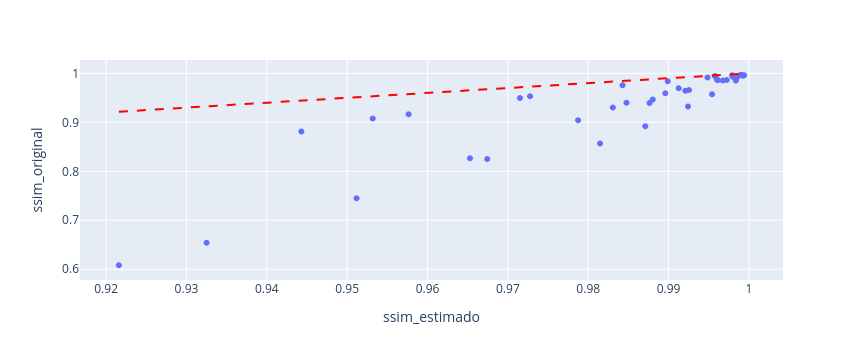

In [47]:
fig = px.scatter(df_merged, x = 'ssim_estimado', y = 'ssim_original', hover_name = df_merged.index)
lo = df_merged['ssim_estimado'].min()
hi = max(df_merged['ssim_estimado'].max(), df_merged['ssim_original'].max())

fig.add_shape(type='line', x0=lo, y0=lo, x1=hi, y1=hi, line=dict(color='red', dash='dash'))
fig.show()

---

# Estimando a SSIM pra cada view de cada LF

Mas antes, vou realizar alguns experimentos para verificar se estou implementando corretamente.
A dedução da estimação da SSIM pela Maria Martini é 

$$
SSIM \approx 1-\frac{MSE_l}{(2\sigma_x^2 + c_2)}
$$

onde tanto $MSE_l$ quanto $\sigma_x^2$ são locais.

No trabalho dela com o Luc, eles propõem outras 3 implementações. A primeira, é uma que não usa informações locais da imagem reconstruída, ou seja, a $MSE_l$ não está disponível, apenas a $MSE_G$. Que fica assim:

$$
SSIM \approx 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}.
$$

Vou começar implementando essa nas próximas células.

Mas, como a SSIM é aplicada por janelas, a $MSE_G$ é insuficiente para approximar a $MSE_l$. Aqui eles desenvolvem uma aproximação da $MSE_l$ a partir da $MSE_G$ com a variância local como primeira ordem de redistribuição global da distorção.

A $MSE_G$ pode ser pensada como um valor esperado da $MSE_l$. Logo, $MSE_G = \mathbb{E}[MSE_l]$.

$$MSE_l \approx MSE_G \frac{\sigma_x^2}{\mathbb{E}[\sigma_x^2]}$$

Eles fizeram uma análise empírica e encontraram que seria interessante colocar um expoente $\beta$:

$$MSE_l \approx MSE_G \frac{(\sigma_x^2 + \epsilon)^\beta}{\mathbb{E}[(\sigma_x^2+\epsilon)^\beta]}$$

onde $\epsilon\ =\ 1e^{-6}$ and $\beta$ ficou em 0.46 e 0.48 para cada dataset que eles usaram. Essa é outra implementação que eles fizeram. 

Como $\beta$ deu valores próximos a $0.5$, eles implementação um quarto cenário onde $\beta = 0.5$ o que resulta na variância se tornar o desvio padrão:

$$MSE_l \approx MSE_G \frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]}$$

Trocando na equação inicial, fica:

$$
SSIM \approx 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}\frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]}
$$

E o SSIM global é calculado pela média de todas as janelas do frame da imagem original.

$$
MSSIM(X, Y) = \approx \frac{1}{M}\sum_j \left ( 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}\frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]} \right)
$$

Vou fazer os mesmos experimentos com as imagens do kodak. E depois com os LFs.

## Getting ready with kodak dataset and some fundamental functions

Primeiro vou começar definindo 2 funções importantes. Uma pra comprimir com JPEG. A outra é pra calcular a MSE de duas imagens.

In [48]:
def jpeg_compress(original, quality = 75):
    buffer = io.BytesIO()
    Image.fromarray(original, 'L').save(buffer, format = "JPEG", quality = quality)
    buffer.seek(0)
    return np.array(Image.open(buffer))

def MSE(original, pred):
    mse = np.mean(np.square(original.astype(np.float64) - pred.astype(np.float64)))
    return mse

Agora vou baixar o dataset do Kodak, direto do kaggle

In [49]:
import kagglehub

# path_kodak_ds = kagglehub.dataset_download("sherylmehta/kodak-dataset")
path_kodak_ds = '/home/andrey/.cache/kagglehub/datasets/sherylmehta/kodak-dataset/versions/1'

print("Path to dataset files:", path_kodak_ds)

Path to dataset files: /home/andrey/.cache/kagglehub/datasets/sherylmehta/kodak-dataset/versions/1


\
Vou passar o nome de cada imagem do kodak pra um txt, e depois armazenar em uma lista.

In [50]:
!ls /home/andrey/.cache/kagglehub/datasets/sherylmehta/kodak-dataset/versions/1 > kodak_images.txt

A seguir temos uma lista com o nome de cada imagem do dataset do kodak

In [51]:
f = open('kodak_images.txt', 'r')
kodak_dataset = f.read().split('\n')[:-1]
kodak_dataset[:10]

['kodim01.png',
 'kodim02.png',
 'kodim03.png',
 'kodim04.png',
 'kodim05.png',
 'kodim06.png',
 'kodim07.png',
 'kodim08.png',
 'kodim09.png',
 'kodim10.png']

## Implementando a SSIM do Luc 

Do [notebook](https://github.com/luctrudeau/approxSSIMate/blob/main/notebooks/01_ssim_psnr_foundations.ipynb) do Luc, eu tirei também a função a seguir de calculo da SSIM. Mas eu tive que dar uma alterada pois a versão dele contempla apenas o uso de um filtro uniforme. E no primeiro artigo da SSIM, eles usam um filtro gaussiano com janela 11x11 e outras características. Por isso, eu a generalizei pra incluir o uso dos dois filtros.

In [52]:
def ssim_luc(original, rec, filtro, win_size=7, data_range=255, k1=0.01, k2=0.03, mse_g = np.nan):
    '''
    Objective: Calculates the original SSIM, with the Gaussian and Uniform filters.
    To use the Gaussian, only need the radius, and sigma. To use the uniform filter, only needs the window size.
    Inputs necessary: Original and reconstructed images and the filter used.
    Returns: the mean of the SSIM for the whole image. a float value'''
    c1 = (k1 * data_range) ** 2
    c2 = (k2 * data_range) ** 2

    original = original.astype(np.float64, copy=False)
    rec = rec.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    if filtro == 'uniform':
        # Local means
        ux = uniform_filter(original, size=win_size)
        uy = uniform_filter(rec, size=win_size)
    
        # Local second moments
        uxx = uniform_filter(original * original, size=win_size)
        uyy = uniform_filter(rec * rec, size=win_size)
        uxy = uniform_filter(original * rec, size=win_size)

    elif filtro == 'gaussian':
        # Local means
        ux = gaussian_filter(original, radius=win_size, sigma = 1.5)
        uy = gaussian_filter(rec, radius=win_size, sigma = 1.5)

        # Local second moments
        uxx = gaussian_filter(original * original, radius=win_size, sigma = 1.5)
        uyy = gaussian_filter(rec * rec, radius=win_size, sigma = 1.5)
        uxy = gaussian_filter(original * rec, radius=win_size, sigma = 1.5)
    
    # Local variances and covariance
    vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)
    vy = np.maximum(cov_norm * (uyy - uy * uy), 0.0)
    vxy = cov_norm * (uxy - ux * uy)

    # SSIM formula
    A1 = 2 * ux * uy + c1
    A2 = 2 * vxy + c2   
    B1 = ux**2 + uy**2 + c1
    B2 = vx + vy + c2

    # Local SSIM
    S = (A1 * A2) / (B1 * B2)

    pad = (win_size - 1) // 2
    # Global SSIM (excluding borders)
    return crop(S, pad).mean(dtype=np.float64)

## Implementação com $MSE_G$

A primeira implementação será com a equação usando a $MSE_G$:

$$
SSIM \approx 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}
$$

In [53]:
def mssim_global(original, mse_g, rec = 0, win_size = 7, data_range=255, k1=.01, k2=.03, filtro = 'uniform'):
    '''
    Objective: Calculate the SSIM based on the global MSE of the original and reconstructed images.
    Inputs necessary: Original image and Global MSE.
    Returns: the mean of the SSIM for the whole image.'''
    c2 = (k2*data_range)**2

    original = original.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    if filtro == 'uniform':
        ux = ndimage.uniform_filter(original, size=win_size)
        uxx = ndimage.uniform_filter(original * original, size=win_size)
        vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)

    elif filtro == 'gaussian':
        ux = ndimage.uniform_filter(original, size=win_size)
        uxx = ndimage.uniform_filter(original * original, size=win_size)
        vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)

    pad = (win_size - 1) // 2
    vx_c = crop(vx, pad)

    mssim = np.mean(1 - mse_g / (2*vx_c + c2))   # média de razões (a sua, sem bordas)

    return mssim

\
Agora vou implementar uma função que deve ser usada pro cálculo de diferentes ssims, tanto a versão original, quanto as estimações.
A ideia é que retorne um data frame cujo index é cada imagem do dataset e as colunas são cada taxa de compressão. Os valores das células são as respectivas ssims calculadas.

def ao_receber_frame(frame):
    # Confirme os nomes dos atributos com dir(frame)
    largura = int(frame.headers['W'])
    altura = int(frame.headers['H'])
    dados = np.frombuffer(frame.buffer, dtype=np.uint8)
    y = dados[:largura * altura].reshape(altura, largura)  # plano Y (luminância)
    frame_.append(y.copy())

In [54]:
def calcular_mssim_por_taxa_por_imagem(funcao_ssim, nome, rec = np.nan, filtro = 'uniforme', dataset = 'kodak'):
    '''
    Objective: calculates the SSIM following a given function to it. But for each compress tax in arange(30, 100, 5).
    Input necessary: the SSIM function, the name of the returned dataframe
    Returns: 2 dataframes, The first contains the mssim for each quality tax, of the whole dataset.
    the second contains the ssims per image and for each compress tax.'''
    qualities = np.arange(30, 101, 5)
    
    ssim_dict_por_taxa_por_imagem = {}
    
    for quality in qualities:
    
        ssim_lista = []

        if dataset == 'kodak':
            for image_name in kodak_dataset:
                
                path_image = path_kodak_ds + '/' + image_name
        
                img_original = Image.open(path_image).convert('L') # L de Luminancia L = R * 299/1000 + G * 587/1000 + B * 114/1000
                img_original = np.array(img_original, dtype = np.uint8)
        
                img_rec = jpeg_compress(img_original, quality = int(quality))
        
                mse_g = MSE(img_original, img_rec)
                
                mssim_de_uma_imagem = funcao_ssim(original = img_original, mse_g = mse_g, rec = img_rec, filtro = filtro)
                
                ssim_lista.append(mssim_de_uma_imagem)
    
            ssim_dict_por_taxa_por_imagem[int(quality)] = ssim_lista

            ssim_df_por_taxa_por_imagem = pd.DataFrame(ssim_dict_por_taxa_por_imagem, index = [n.replace('.png', '') for n in kodak_dataset])
            ssim_df_por_taxa_por_imagem.index = ['kodim' + str(i) for i in range(24)]

        elif dataset == 'subset':
            
            for img in subset_dataset:
                frame_.clear()

                with open(path_subset + img, 'rb') as f:
                    header = f.readline().decode('ascii')
                    tokens = header.split()
                    w = int(next(t[1:] for t in tokens if t.startswith('W')))
                    h = int(next(t[1:] for t in tokens if t.startswith('H')))
                
                    f.readline()  # pula a linha "FRAME\n"
                    Y = np.frombuffer(f.read(w * h), dtype=np.uint8).reshape(h, w)

                img_original = Y
                img_original = np.array(img_original, dtype = np.uint8)

                img_rec = jpeg_compress(img_original, quality = int(quality))
                mse_g = MSE(img_original, img_rec)

                mssim_de_uma_imagem = funcao_ssim(original = img_original, mse_g = mse_g, rec = img_rec, filtro = filtro)

                ssim_lista.append(mssim_de_uma_imagem)

            ssim_dict_por_taxa_por_imagem[int(quality)] = ssim_lista

            ssim_df_por_taxa_por_imagem = pd.DataFrame(ssim_dict_por_taxa_por_imagem, index = [n.replace('.y4m', '') for n in subset_dataset])
            ssim_df_por_taxa_por_imagem.index = ['subset' + str(i) for i in range(len(subset_dataset))]


    return ssim_df_por_taxa_por_imagem

In [55]:
df_luc = calcular_mssim_por_taxa_por_imagem(ssim_luc, nome = 'mssim_luc', filtro = 'uniform')
df_luc.head()

,30,35,40,45,50,55,60,65,70,75,80,85,90,95,100
kodim0,0.861339,0.875195,0.885985,0.895559,0.903060,0.910166,0.918015,0.926008,0.935548,0.944534,0.955443,0.967089,0.979847,0.992167,0.999696
kodim1,0.852940,0.865970,0.874944,0.883361,0.890620,0.896776,0.904704,0.912622,0.920953,0.929555,0.939955,0.951281,0.965161,0.982258,0.999182
kodim2,0.909747,0.918641,0.925135,0.931285,0.936460,0.940742,0.945531,0.950513,0.956141,0.961051,0.967029,0.973477,0.980475,0.988166,0.999043
kodim3,0.878473,0.890035,0.898004,0.905207,0.911143,0.916675,0.922582,0.928777,0.935469,0.942117,0.950571,0.959923,0.971168,0.985036,0.999291
kodim4,0.897859,0.909409,0.917820,0.925463,0.931508,0.937110,0.943143,0.949261,0.956075,0.962560,0.970087,0.977920,0.986004,0.994015,0.999731


In [56]:
df_ssim_global = calcular_mssim_por_taxa_por_imagem(mssim_global, nome = 'mssim_global', filtro = 'uniform')
df_ssim_global.head()

,30,35,40,45,50,55,60,65,70,75,80,85,90,95,100
kodim0,0.711247,0.742391,0.765165,0.786039,0.802500,0.818297,0.835654,0.853654,0.873697,0.893550,0.916959,0.941334,0.967070,0.989417,0.999697
kodim1,0.730490,0.757556,0.775571,0.792591,0.807228,0.820921,0.836499,0.852430,0.869006,0.885600,0.905428,0.926880,0.951483,0.978677,0.999177
kodim2,0.757626,0.784235,0.803569,0.821783,0.837213,0.850617,0.864615,0.879291,0.895149,0.910302,0.927892,0.946297,0.965432,0.983940,0.999038
kodim3,0.773399,0.797513,0.814262,0.829361,0.841631,0.852800,0.864773,0.877459,0.891009,0.904609,0.921544,0.939652,0.960218,0.982450,0.999289
kodim4,0.746830,0.778499,0.801856,0.822510,0.839149,0.854559,0.870551,0.887261,0.904758,0.921591,0.940466,0.958804,0.976499,0.991809,0.999731


Vou começar comparando os valores pra $SSIM(MSE_G)$ e a SSIM do luc

In [57]:
luc_medias = df_luc.mean(axis = 0)
luc_std = df_luc.std(axis = 0)

global_medias = df_ssim_global.mean(axis = 0)
global_std = df_ssim_global.std(axis = 0)

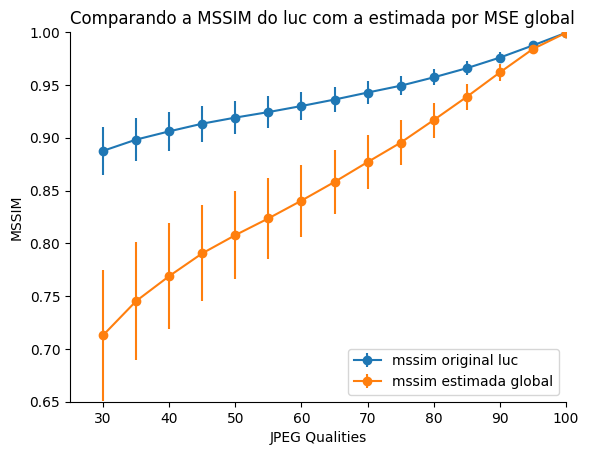

In [58]:
plt.errorbar(df_luc.columns, luc_medias, yerr = luc_std, fmt = '-o', label = 'mssim original luc')
plt.errorbar(df_luc.columns, global_medias, yerr = global_std, fmt = '-o', label = 'mssim estimada global')
plt.legend(loc = 'lower right')

plt.title('Comparando a MSSIM do luc com a estimada por MSE global', loc = 'left')
plt.xlabel('JPEG Qualities')
plt.ylabel('MSSIM')
plt.xlim([25, 100]);
plt.ylim([0.65, 1]);

## Implementação com a $MSE_l$ estimada para $\beta \neq 0.5$ 

Lembrando que a equação a ser implementada é

$$MSE_l \approx MSE_G \frac{(\sigma_x^2 + \epsilon)^\beta}{\mathbb{E}[(\sigma_x^2+\epsilon)^\beta]}$$

In [59]:
def ssim_beta(original, mse_g, rec = 0, win_size=7, data_range = 255, k1=.01, k2=.03, filtro = ''):
    c2 = (k2*data_range)**2

    original = original.astype(np.float64, copy=False)

    NP = win_size * win_size
    cov_norm = NP / (NP - 1)

    ux = ndimage.uniform_filter(original, size=win_size)
    uxx = ndimage.uniform_filter(original * original, size=win_size)
    vx = np.maximum(cov_norm * (uxx - ux * ux), 0.0)

    pad = (win_size - 1) // 2
    vx_c = crop(vx, pad)

    epsilon = 1e-6
    vx_epsilon_beta = (vx_c + epsilon)**beta
    valor_esperado = np.mean(vx_epsilon_beta)
    mse_l = (mse_g/valor_esperado)*vx_epsilon_beta
    
    mssim = np.mean(1 - mse_l / (2*vx_c + c2))   # média de razões (a sua, sem bordas)

    return mssim

In [60]:
beta = 0.46
df_ssim_beta_046 = calcular_mssim_por_taxa_por_imagem(ssim_beta, nome = 'ssim_beta_046')
df_ssim_beta_046.head()

,30,35,40,45,50,55,60,65,70,75,80,85,90,95,100
kodim0,0.880058,0.892995,0.902455,0.911125,0.917963,0.924525,0.931734,0.939211,0.947537,0.955783,0.965506,0.975632,0.986322,0.995604,0.999874
kodim1,0.845197,0.860743,0.871091,0.880867,0.889274,0.897139,0.906087,0.915238,0.924758,0.934290,0.945679,0.958001,0.972133,0.987753,0.999527
kodim2,0.890633,0.902639,0.911364,0.919582,0.926545,0.932594,0.938910,0.945532,0.952688,0.959525,0.967462,0.975767,0.984402,0.992753,0.999566
kodim3,0.874986,0.888290,0.897530,0.905860,0.912630,0.918791,0.925397,0.932395,0.939871,0.947374,0.956717,0.966707,0.978053,0.990318,0.999608
kodim4,0.893864,0.907140,0.916932,0.925591,0.932566,0.939027,0.945731,0.952736,0.960072,0.967129,0.975042,0.982729,0.990147,0.996566,0.999887


In [61]:
beta046_medias = df_ssim_beta_046.mean(axis = 0)
beta046_std = df_ssim_beta_046.std(axis = 0)

## Implementação com a $MSE_l$ estimada para $\beta = 0.5$

In [62]:
beta = 0.5
df_ssim_beta_050 = calcular_mssim_por_taxa_por_imagem(ssim_beta, nome = 'ssim_beta_050')

In [63]:
beta050_medias = df_ssim_beta_050.mean(axis = 0)
beta050_std = df_ssim_beta_050.std(axis = 0)

## "Implementando" a função do Luc com filtro gaussiano e janela 11x11 (Zhou Wang, 2004)

In [64]:
df_ssim_gaussiano = calcular_mssim_por_taxa_por_imagem(ssim_luc, nome = 'ssim Bovik', filtro = 'gaussian')
gaussiano_medias = df_ssim_gaussiano.mean(axis = 0)
gaussiano_std = df_ssim_gaussiano.std(axis = 0)

## Comparando as implementações

In [65]:
qualities = np.arange(30, 101, 5)

def comparando_implementacoes(medias, labels, cores, erros, titulo):
    fig, ax = plt.subplots(figsize = (5, 5))

    if erros != 0:
        for media, erro, label, cor in zip (medias, erros, labels, cores):
            ax.errorbar(qualities, media, erro, fmt = '-o', label = label, color = cor)
    else:
        for media, label, cor in zip (medias, labels, cores):
            ax.plot(qualities, media, '-o', label = label, color = cor)
    
    ax.legend()
    ax.grid()
    
    ax.set_title(titulo, loc = 'left')
    ax.set_xlabel('JPEG Quality')
    xticks = [40, 60, 80, 100]
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticks)
    ax.set_ylabel('MSSIM')
    yticks = [0.70, 0.80, 0.90, 1.00]
    ax.set_yticks(yticks)
    ax.set_yticklabels(yticks)
    ax.set_ylim([0.65, 1.0]);
    ax.set_xlim([25, 105]);

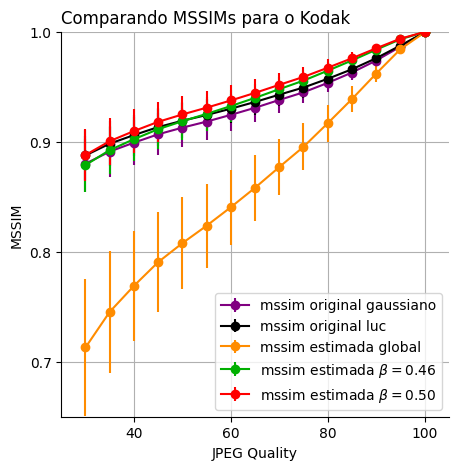

In [66]:
d = {'mssim original gaussiano': [gaussiano_medias, gaussiano_std, '#800080'],
     'mssim original luc': [luc_medias, luc_std, '#000'],
     'mssim estimada global': [global_medias, global_std, '#FF8C00'],
      r'mssim estimada $\beta = 0.46$': [beta046_medias, beta046_std, '#00AF00'],
      r'mssim estimada $\beta = 0.50$': [beta050_medias, beta050_std, '#FF0000']}

comparando_implementacoes(medias = [v[0] for v in d.values()], labels = d.keys(),
                          cores = [v[2] for v in d.values()], erros = [v[1] for v in d.values()], 
                          titulo = 'Comparando MSSIMs para o Kodak')

### Verificando o erro relativo

In [67]:
def erros_relativos(df_e, df_o):

    erro_relativo = (df_e - df_o)/df_o
    erro_relativo_medias = erro_relativo.mean()
    erro_relativo_std = erro_relativo.std()
    
    return erro_relativo_medias, erro_relativo_std

In [68]:
dicionario = {'df_ssim_global': [df_ssim_global, global_std, '#00AF00'], 
              'df_ssim_beta_046': [, 
              'df_ssim_beta_050', 
              'gaussiano_std'}

medias = erros_relativos_df.values()
erros = [gaussiano_std, luc_std, global_std, beta046_std, beta050_std]
labels = erros_relativos_df.keys()
cores = ['#800080', '#000', "#FF8C00", '#00AF00', '#FF0000']

comparando_implementacoes(medias, labels, cores, erros = erros, titulo = 'Comparando MSSIMs para o Kodak')

SyntaxError: closing parenthesis '}' does not match opening parenthesis '[' on line 2 (1310499593.py, line 4)

In [ ]:
colors = ['#FF8C00', '#00AF00', '#FF0000', '#800080']
labels = [r'mssim estimada global', r'mssim estimada $\beta = 0.46$', r'mssim estimada $\beta = 0.50$', r'ssim gaussiano']
fig, ax = plt.subplots(figsize = (5, 5))

for df, color, label in zip(erros_relativos_dfs.keys(), colors, labels):
    print(df, color, label)
    ax.errorbar(qualities, erros_relativos_dfs[df][0], erros_relativos_dfs[df][1], fmt = '-o', label = rf'{label}', color = color)

ax.legend(loc = 'lower right')
ax.grid()
ax.set_title('Erro Relativo dos MSSIM com relação ao MSSIM do Luc')
ax.set_xlabel('JPEG Quality')
xticks = [40, 60, 80, 100]
ax.set_xticks(xticks)
ax.set_xticklabels(xticks)
ax.set_ylabel('MSSIM Delta (%)')
ticks=[-.3, -.05, -.03, -.01, -.005, 0, .005, .01]
ax.set_yticks(ticks)
ax.set_yticklabels(ticks)
ax.set_xlim([25, 105]);

---

## Implementando com a SSIM do VMAF

## Testando pras imagens do Subset1

Primeiro vou obter o caminho pra elas

In [ ]:
!ls /home/andrey/Downloads/subset1-y4m/ > subset1_images.txt

In [69]:
f = open('subset1_images.txt', 'r')
path_subset = '/home/andrey/Downloads/subset1-y4m/'
subset_dataset = f.read().split('\n')
subset_dataset = [i for i in subset_dataset if '.y4m' in i]
subset_dataset[:10]

['08-2011._Panthera_tigris_tigris_-_Texas_Park_-_Lanzarote_-TP04.y4m',
 '125_-_Québec_-_Pont_de_Québec_de_nuit_-_Septembre_2009.y4m',
 '2011-03-05_03-13_Madeira_159_Funchal,_Mercado_dos_Lavradores.y4m',
 '205_-_Vallée_de_Colca_-_Panorama_-_Juin_2010_-_5_de_6.y4m',
 '89_-_Vézelay_Basilique_2.y4m',
 'Abandoned_Packard_Automobile_Factory_Detroit_200.y4m',
 'Adventure_with_the_Windmills.y4m',
 'Air_Force_Academy_Chapel,_Colorado_Springs,_CO_04090u_original.y4m',
 'Albi,_Cathédrale_Sainte_Cécile_(3).y4m',
 'Bath_from_alexandra_park.y4m']

In [71]:
frame_ = []
df_luc_s = calcular_mssim_por_taxa_por_imagem(ssim_luc, nome = 'mssim_luc_s', filtro = 'uniform', dataset = 'subset')

df_ssim_global_s = calcular_mssim_por_taxa_por_imagem(mssim_global, nome = 'mssim_global_s', filtro = 'uniform', dataset = 'subset')

beta = 0.48
df_ssim_beta_048_s = calcular_mssim_por_taxa_por_imagem(ssim_beta, nome = 'ssim_beta_048_s', dataset = 'subset')

beta = 0.50
df_ssim_beta_050_s = calcular_mssim_por_taxa_por_imagem(ssim_beta, nome = 'ssim_beta_050_s', dataset = 'subset')

df_ssim_gaussiano_s = calcular_mssim_por_taxa_por_imagem(ssim_luc, nome = 'ssim Bovik_s', filtro = 'gaussian', dataset = 'subset')

In [74]:
luc_medias_s = df_luc_s.mean(axis = 0)
luc_std_s = df_luc_s.std(axis = 0)

global_medias_s = df_ssim_global_s.mean(axis = 0)
global_std_s = df_ssim_global_s.std(axis = 0)

beta048_medias_s = df_ssim_beta_048_s.mean(axis = 0)
beta048_std_s = df_ssim_beta_048_s.std(axis = 0)

beta050_medias_s = df_ssim_beta_050_s.mean(axis = 0)
beta050_std_s = df_ssim_beta_050_s.std(axis = 0)

gaussiano_medias_s = df_ssim_gaussiano_s.mean(axis = 0)
gaussiano_std_s = df_ssim_gaussiano_s.std(axis = 0)

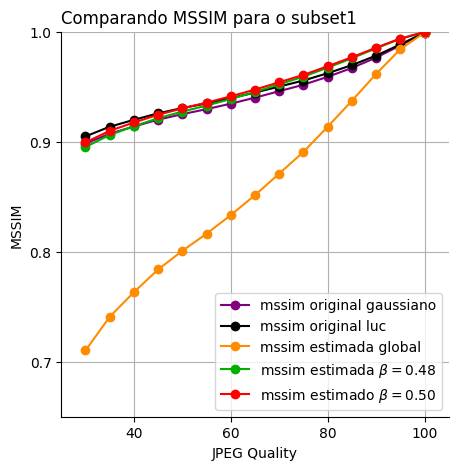

In [75]:
d = {
    'mssim original gaussiano': [gaussiano_medias_s, gaussiano_std_s, '#800080'],
    'mssim original luc': [luc_medias_s, luc_std_s, '#000'],
    'mssim estimada global': [global_medias_s, global_std_s, '#FF8C00'],
    r'mssim estimada $\beta = 0.48$': [beta048_medias_s, beta048_std_s, '#00AF00'],
    r'mssim estimado $\beta = 0.50$': [beta050_medias_s, beta050_std_s, '#FF0000']
}

comparando_implementacoes(medias = [v[0] for v in d.values()], labels = d.keys(),
                          cores = [v[2] for v in d.values()], erros = 0,
                          titulo = 'Comparando MSSIM para o subset1')

## Erro relativo Subset1

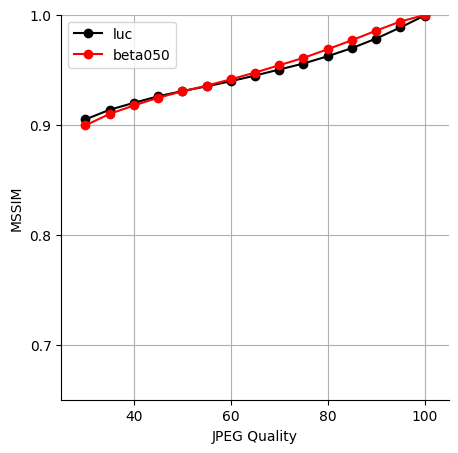

In [76]:
comparando_implementacoes(medias = [luc_medias_s, beta050_medias_s], labels = ['luc', 'beta050'], cores = ['#000', '#F00'], erros = 0, titulo = '')

In [81]:
dif_media050 = -1*((df_ssim_beta_050_s - df_luc_s)/df_luc_s).mean()*100
dif_std_050 = ((df_ssim_beta_050_s - df_luc_s)/df_luc_s).std()*100

dif_media048 = -1*((df_ssim_beta_048_s - df_luc_s)/df_luc_s).mean()*100
dif_std_048 = ((df_ssim_beta_050_s - df_luc_s)/df_luc_s).std()*100

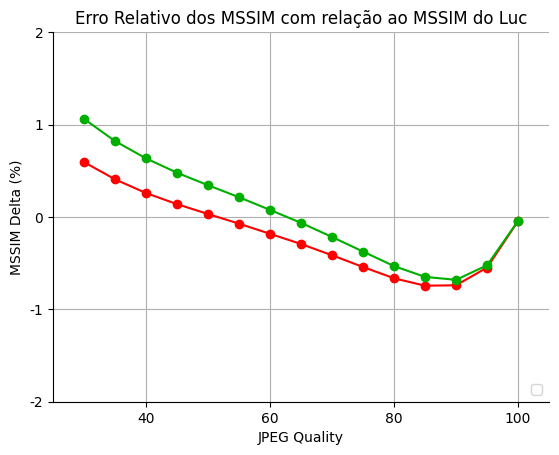

In [84]:
fig, ax = plt.subplots()

# ax.errorbar(dif_media050.index, dif_media050.values, dif_std_050, color = '#F00')
# ax.errorbar(dif_media048.index, dif_media048.values, dif_std_048, color = '#00AF00')
ax.plot(dif_media050.index, dif_media050.values, '-o', color = '#F00')
ax.plot(dif_media048.index, dif_media048.values, '-o', color = '#00AF00')


ax.legend(loc = 'lower right')
ax.grid()
ax.set_title('Erro Relativo dos MSSIM com relação ao MSSIM do Luc')
ax.set_xlabel('JPEG Quality')
xticks = [40, 60, 80, 100]
ax.set_xticks(xticks)
ax.set_xticklabels(xticks)
ax.set_ylabel('MSSIM Delta (%)')
ticks=[-2, -1, 0, 1, 2]
ax.set_yticks(ticks)
ax.set_yticklabels(ticks)
ax.set_xlim([25, 105]);

## Agora que vi que deu certo, vou implementar pra Light Field

O MSE pra cada view pode ser calculado, eu acho. Mas eu já tenho o $PSNR_y$ de cada view. Por isso, vou usar a definição de PSNR:

$$
PSNR = 10 log_{10}\frac{(2^b - 1)^2}{MSE}
$$

Reescrevendo as equações anteriores em função do PSNR. A primeira equação de estimação do SSIM, deduzida pela Maria Martini é $SSIM \approx 1-\frac{MSE_l}{(2\sigma_x^2 + c_2)}$. Que fica, 

$$
SSIM \approx 1-\frac{(2^b - 1)^2}{(2\sigma_x^2 + c_2)(10^{\text{PSNR}/10})}
$$

---



onde tanto $MSE_l$ quanto $\sigma_x^2$ são locais.

A primeira equação de estimação pro $MSE_l$ com o parâmetro livre $beta$ fica:

$$MSE_l \approx MSE_G \frac{(\sigma_x^2 + \epsilon)^\beta}{\mathbb{E}[(\sigma_x^2+\epsilon)^\beta]}$$

onde $\epsilon\ =\ 1e^{-6}$ and $\beta$ ficou em 0.46 e 0.48 para cada dataset que eles usaram. Essa é outra implementação que eles fizeram. 

Como $\beta$ deu valores próximos a $0.5$, eles implementação um quarto cenário onde $\beta = 0.5$ o que resulta na variância se tornar o desvio padrão:

$$MSE_l \approx MSE_G \frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]}$$

Trocando na equação inicial, fica:

$$
SSIM \approx 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}\frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]}
$$

E o SSIM global é calculado pela média de todas as janelas do frame da imagem original.

$$
MSSIM(X, Y) = \approx \frac{1}{M}\sum_j \left ( 1-\frac{MSE_G}{(2\sigma_x^2 + c_2)}\frac{(\sigma_x + \epsilon)}{\mathbb{E}[\sigma_x + \epsilon]} \right)
$$

# Entendendo como funciona o yuvio

In [ ]:
import yuvio

In [ ]:
# aqui temos os diretórios de todos os LFs
!ls ../lfctest/ce/results/jplm_ssim_estimate_results/ 

\
Quero ver alguns documentos decodados do LF Bikes

In [ ]:
!ls ../lfctest/ce/results/jplm_ssim_estimate_results/Bikes/decoded/yuv/

Agora quero ver todos os yuv's decodados de todos os LFs

In [ ]:
!ls ../lfctest/ce/results/jplm_ssim_estimate_results/*/decoded/yuv/

Vou passar todos esses caminhos, apenas os .yuv's, pra um txt que vou ler depois

In [ ]:
!ls ../lfctest/ce/results/jplm_ssim_estimate_results/*/decoded/yuv/*.yuv > path_de_todos_os_lfs_decodados.txt

Vou acessar o Bikes_015 e gerar a imagem com yuvio

- a função `.imread` retorna uma view do yuv do arquivo

In [ ]:
path_bikes_yuv = '../lfctest/ce/results/jplm_ssim_estimate_results/Bikes/decoded/yuv/'

bikes015 = 'Bikes_015_11_11_625x434_yuv444p10le.yuv'
bikes015_path = path_bikes_yuv + bikes015

BikesLFyuv = yuvio.imread(bikes015_path, 625, 434, 'yuv444p10le')
img = BikesLFyuv.y
plt.imshow(img);

- a função `.mimread` retorna uma lista com todas as views do yuv do arquivo

In [ ]:
bikes015 = 'Bikes_015_11_11_625x434_yuv444p10le.yuv'
bikes015_path = path_bikes_yuv + bikes015

BikesLFyuv = yuvio.mimread(bikes015_path, 625, 434, 'yuv444p10le')

# for i in range(len(BikesLFyuv)):
view_y = BikesLFyuv[0].y
plt.imshow(view_y)
# ssims_estimada_por_view = []

# for i in range(len(BikesLFyuv)):
#     view_y = BikesLFyuv[i].y
#     ssims_estimada_por_view.append(ssim_luc(psnr = psnr_df.loc['Bikes_015'].iloc[i], reconstruida = view_y))

# print('estimada ', np.mean(ssims_estimada_por_view))
# print(ssims_medias_por_lf['Bikes_015'])

In [ ]:
fig, ax = plt.subplots()
x = np.arange(len(ssim_dict_of_each_LF['Bikes_015']))
ax.scatter(ssims_estimada_por_view, ssim_dict_of_each_LF['Bikes_015'], label = 'original')
ax.legend();

Eu consegui comparar as ssims originais com a estimada do Bikes015. Mas a estimada é pro bloco todo. O gráfico acima mostra o resultado. Vou aplicar o calculo da ssim estimada por blocos.

Na próxima célula quero entender como funcionam os filtros nas imagens com `scipy`. Tanto o filtro uniforme, usado pelo luc, quanto o filtro gaussiano usado no paper do Zhou Wang de 2004

In [ ]:
fig = plt.figure()

reader = BikesLFyuv
original = reader[0].y # datasets.ascent()

win_size = 7
uniform = ndimage.uniform_filter(original, size = win_size)
gaussian = ndimage.gaussian_filter(original, sigma = 1.5, radius = 5) # sigma é o standard deviation do paper de 2004
uyy = ndimage.uniform_filter(original * original, size=win_size)

difference = uniform - uyy

ax1 = fig.add_subplot(141) # left
ax2 = fig.add_subplot(142) # middle left
ax3 = fig.add_subplot(143) # middle right
ax4 = fig.add_subplot(144) # right

ax1.imshow(original)
ax2.imshow(uniform)
ax3.imshow(uyy)
ax4.imshow(difference)
plt.show()